# 07. SHAP Analysis

## 1. 분석 환경 설정

본 단계에서는 머신러닝 모델의 예측 결과를 해석하기 위해 SHAP(SHapley Additive exPlanations)을 활용한다.

SHAP은 각 변수가 모델의 예측값에 미치는 기여도를 계산하여 모델의 의사결정 과정을 설명하는 방법이다.

본 분석에서는 직원 이직 예측 모델을 대상으로 주요 변수의 영향력과 개별 예측 사례를 분석한다.

> **데이터 출처·라이선스:** IBM HR Analytics Employee Attrition & Performance(IBM 데이터 과학자가 만든 가상 데이터. [Kaggle](https://www.kaggle.com/datasets/pavansubhasht/ibm-hr-analytics-attrition-dataset), [IBM/employee-attrition-aif360](https://github.com/IBM/employee-attrition-aif360)). 데이터베이스는 [ODbL 1.0](https://opendatacommons.org/licenses/odbl/1-0/), 개별 내용은 [DbCL 1.0](https://opendatacommons.org/licenses/dbcl/1-0/)으로 표기되어 있습니다. 이 Notebook의 출력(표·그림·수치)은 이 데이터에서 만든 결과물이며, MIT License(`../LICENSE`)는 코드에만 적용됩니다. 전처리 CSV(ODbL 1.0)와 전처리 방법은 `../data/README.md`를 참고하세요.
>
> Contains information from the IBM HR Analytics Employee Attrition & Performance dataset, which is made available here under the Open Database License (ODbL) 1.0.

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import shap
import joblib
import warnings

warnings.filterwarnings("ignore")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.unicode_minus"] = False

sns.set_theme(style="whitegrid")

## 2. 데이터 및 모델 로드

전처리가 완료된 HR 데이터를 불러오고, 06번 머신러닝 단계에서 저장한 최종 모델을 로드한다.

동일한 학습 및 테스트 데이터 분할 조건을 재현하여 테스트 데이터를 SHAP 분석 대상으로 활용한다.

In [2]:
# 전처리 완료 데이터 로드
hr_df = pd.read_csv(
    "../data/processed/hr_preprocessed.csv"
)

# 입력 변수와 타깃 변수 분리
drop_cols = [
    "Attrition",
    "AttritionBinary",
    "EmployeeNumber"
]

X = hr_df.drop(columns=drop_cols)
y = hr_df["Attrition"].map({"Yes": 1, "No": 0})

# 기존과 동일한 데이터 분할
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2020158011,
    stratify=y
)

# 최종 모델 로드
best_rf = joblib.load(
    "../models/best_rf_optuna.pkl"
)

print("데이터 크기:", hr_df.shape)
print("학습 데이터:", X_train.shape)
print("테스트 데이터:", X_test.shape)

print("모델 로드 완료")

데이터 크기: (1470, 34)
학습 데이터: (1176, 31)
테스트 데이터: (294, 31)
모델 로드 완료


## 3. SHAP 분석 데이터 준비

저장된 머신러닝 파이프라인을 활용하여 테스트 데이터를 변환한다.

모델에 입력된 최종 변수명과 SHAP 분석 결과의 변수명을 일치시켜 해석의 정확성을 확보한다.

본 분석에서는 테스트 데이터를 대상으로 SHAP 값을 계산하여 모델의 예측 결과를 해석한다.

In [3]:
# 저장된 파이프라인에서 전처리기 추출
preprocessor = best_rf.named_steps["preprocessor"]

# Random Forest 모델 추출
rf_model = best_rf.named_steps["classifier"]

# 테스트 데이터 전처리
X_test_processed = preprocessor.transform(X_test)

# SHAP 분석용 데이터 변환
if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# 전처리 후 변수명
feature_names = preprocessor.get_feature_names_out()

# DataFrame 생성
X_test_shap = pd.DataFrame(
    X_test_processed,
    columns=feature_names,
    index=X_test.index
)

print("SHAP 분석 데이터 크기:", X_test_shap.shape)

display(X_test_shap.head())

SHAP 분석 데이터 크기: (294, 56)


,num__Age,num__DailyRate,num__DistanceFromHome,num__Education,num__EnvironmentSatisfaction,num__HourlyRate,num__JobInvolvement,num__JobLevel,num__JobSatisfaction,num__MonthlyIncome,...,cat__MaritalStatus_Divorced,cat__MaritalStatus_Married,cat__MaritalStatus_Single,cat__OverTime_No,cat__OverTime_Yes,cat__TenureGroup_0-1 Years,cat__TenureGroup_2-3 Years,cat__TenureGroup_4-5 Years,cat__TenureGroup_6-10 Years,cat__TenureGroup_Over 10 Years
1397,1.837355,-1.614343,-0.027807,-0.900057,-1.587237,0.064323,0.377939,-0.076809,0.241728,-0.768992,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
883,-0.449246,-1.708920,-0.027807,0.067463,-1.587237,-0.279512,0.377939,-0.971137,1.149948,-0.793248,...,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
559,0.095182,-1.333101,-0.885137,2.002504,1.178082,1.292306,0.377939,-0.971137,0.241728,-0.735536,...,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0
1037,0.857383,1.603765,2.421708,0.067463,-0.665464,-0.525109,0.377939,0.817519,1.149948,0.586620,...,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
521,-1.102561,1.509188,-0.762662,-1.867577,1.178082,0.260800,1.775599,-0.076809,1.149948,-0.403063,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


## 4. SHAP Value 계산

SHAP TreeExplainer를 활용하여 Random Forest 모델의 예측 결과를 설명한다.

TreeExplainer는 트리 기반 머신러닝 모델의 SHAP 값을 효율적으로 계산할 수 있는 방법이다.

각 변수의 SHAP 값은 해당 변수가 모델의 예측값에 얼마나 기여했는지를 나타낸다.

In [4]:
# TreeExplainer 생성
explainer = shap.TreeExplainer(rf_model)

# SHAP 값 계산
shap_values = explainer.shap_values(X_test_shap)

print("SHAP 값 계산 완료")
print("SHAP 결과 형태:", np.array(shap_values).shape)

SHAP 값 계산 완료
SHAP 결과 형태: (294, 56, 2)


In [5]:
# 이직 클래스(1)의 SHAP 값 추출
if isinstance(shap_values, list):
    attrition_shap_values = shap_values[1]
elif len(shap_values.shape) == 3:
    attrition_shap_values = shap_values[:, :, 1]
else:
    attrition_shap_values = shap_values

print("이직 클래스 SHAP 형태:", attrition_shap_values.shape)
print("분석 데이터 형태:", X_test_shap.shape)

이직 클래스 SHAP 형태: (294, 56)
분석 데이터 형태: (294, 56)


## 5. Global Feature Importance

전체 테스트 데이터를 기준으로 각 변수의 평균 절대 SHAP 값을 계산한다.

평균 절대 SHAP 값이 높을수록 해당 변수가 모델의 예측 결과에 상대적으로 큰 영향을 미쳤음을 의미한다.

이를 통해 직원 이직 예측에 중요한 변수의 우선순위를 파악한다.

In [6]:
# 평균 절대 SHAP 값 계산
shap_importance = pd.DataFrame({
    "Feature": X_test_shap.columns,
    "Mean_ABS_SHAP": np.abs(attrition_shap_values).mean(axis=0)
})

# 중요도 순위
shap_importance = shap_importance.sort_values(
    "Mean_ABS_SHAP",
    ascending=False
).reset_index(drop=True)

display(
    shap_importance.head(20).style
    .background_gradient(
        cmap="YlGnBu",
        subset=["Mean_ABS_SHAP"]
    )
    .format({"Mean_ABS_SHAP": "{:.5f}"})
)

,Feature,Mean_ABS_SHAP
0,cat__OverTime_Yes,0.04719
1,cat__OverTime_No,0.04688
2,num__MonthlyIncome,0.03432
3,num__StockOptionLevel,0.03257
4,num__JobLevel,0.03084
5,num__Age,0.02564
6,num__TotalWorkingYears,0.01989
7,num__YearsAtCompany,0.01971
8,num__EnvironmentSatisfaction,0.01940
9,cat__MaritalStatus_Single,0.01573


## 6. 주요 변수 중요도 시각화

평균 절대 SHAP 값을 기준으로 상위 15개 변수를 시각화한다.

이를 통해 모델이 이직 여부를 예측하는 과정에서 중요하게 활용한 변수를 직관적으로 확인한다.

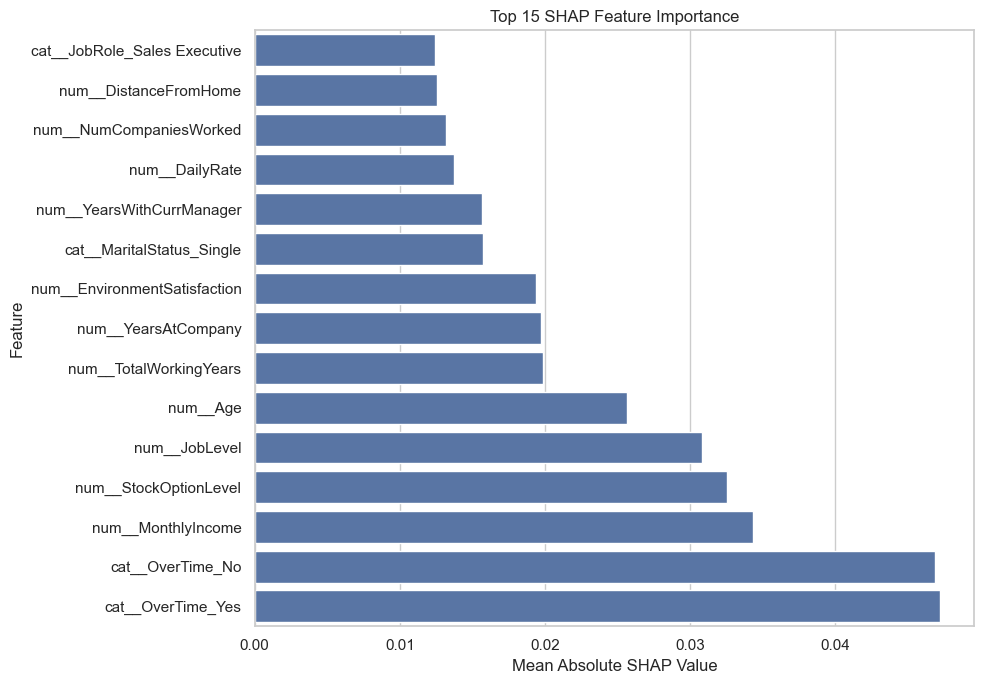

In [7]:
top_features = shap_importance.head(15).sort_values(
    "Mean_ABS_SHAP",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Mean_ABS_SHAP",
    y="Feature"
)

plt.title("Top 15 SHAP Feature Importance")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 8. SHAP Summary Plot 분석

앞서 확인한 SHAP Feature Importance는 각 변수의 평균적인 영향력 크기를 보여준다.

이번 단계에서는 SHAP Summary Plot을 통해 개별 관측치에서 각 변수가 예측 결과에 미치는 영향의 방향과 크기를 확인한다.

이를 통해 다음 질문을 분석한다.

- 어떤 변수의 높은 값이 이직 예측을 높이는가?
- 어떤 변수의 낮은 값이 이직 예측을 높이는가?
- 특정 변수는 관측치에 따라 서로 다른 방향으로 작용하는가?

단, SHAP 값은 모델의 예측 기여도를 나타내며 실제 이직의 원인을 의미하지 않는다.

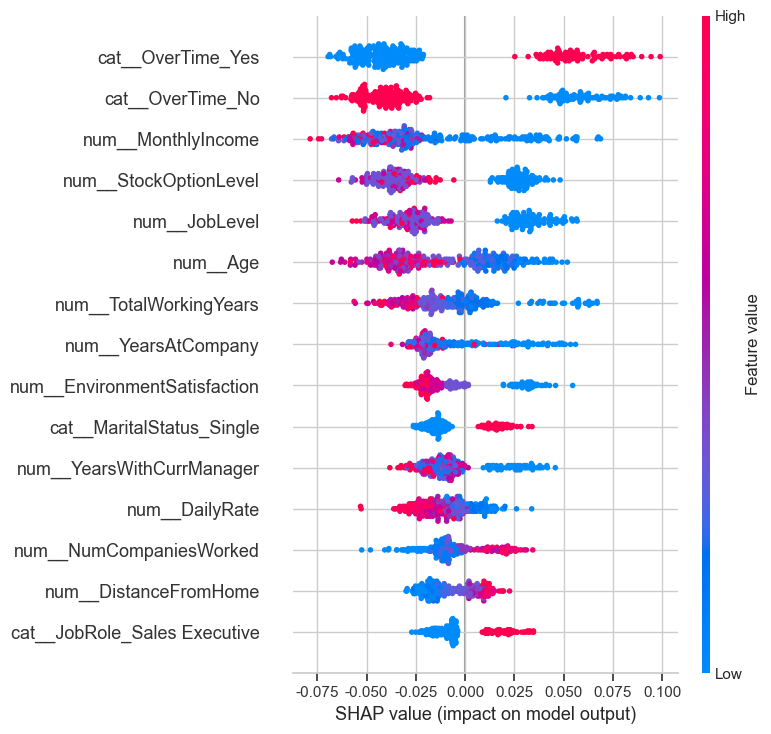

In [8]:
shap.summary_plot(
    attrition_shap_values,
    X_test_shap,
    max_display=15
)

## 9. 주요 변수별 SHAP Dependence 분석

SHAP Summary Plot에서 확인한 주요 변수들을 대상으로
개별 변수의 실제 값과 SHAP 값 사이의 관계를 분석한다.

분석 대상은 다음과 같다.

- 초과근무 여부
- 월 소득
- 스톡옵션 수준
- 연령

이를 통해 각 변수의 값이 변화할 때 이직 예측에 미치는 영향이
어떻게 달라지는지 구체적으로 확인한다.

단, 분석 결과는 모델의 예측 패턴이며 인과관계를 의미하지 않는다.

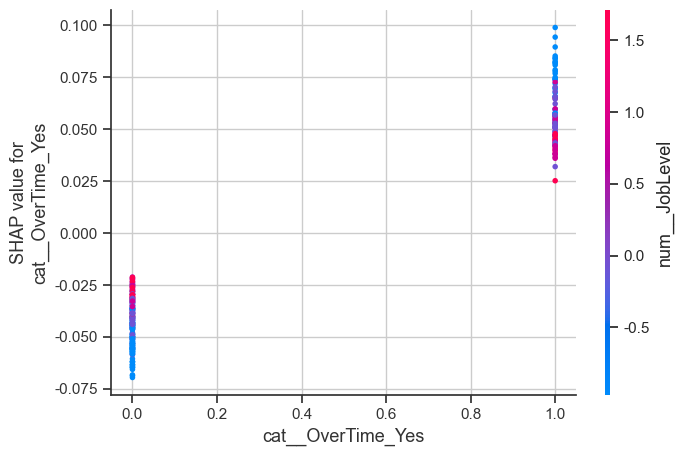

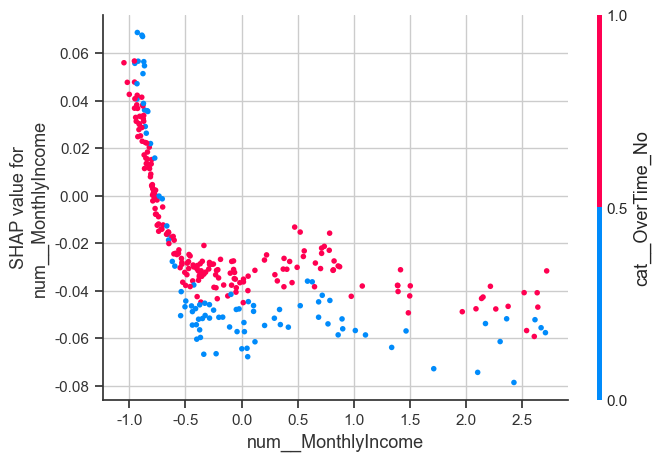

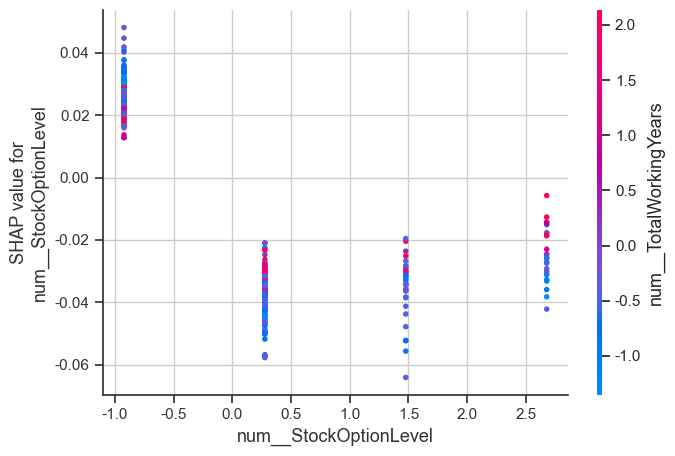

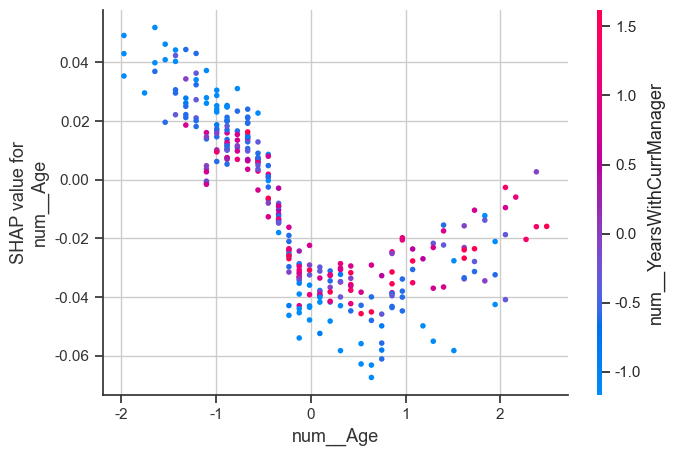

In [9]:
# 1. 초과근무 여부
shap.dependence_plot(
    "cat__OverTime_Yes",
    attrition_shap_values,
    X_test_shap
)

# 2. 월 소득
shap.dependence_plot(
    "num__MonthlyIncome",
    attrition_shap_values,
    X_test_shap
)

# 3. 스톡옵션 수준
shap.dependence_plot(
    "num__StockOptionLevel",
    attrition_shap_values,
    X_test_shap
)

# 4. 연령
shap.dependence_plot(
    "num__Age",
    attrition_shap_values,
    X_test_shap
)

## 10. SHAP Dependence Plot 분석 결과

주요 변수의 SHAP Dependence Plot을 통해 개별 변수의 값과
이직 예측 기여도 사이의 관계를 분석하였다.

### 주요 분석 결과

1. OverTime
   - 초과근무를 수행하는 직원은 양의 SHAP 값을 보이는 경향이 나타났다.
   - 초과근무 여부가 이직 예측에 가장 큰 영향을 미치는 변수로 확인되었다.

2. MonthlyIncome
   - 월 소득이 낮은 구간에서 양의 SHAP 값이 상대적으로 높게 나타났다.
   - 소득이 증가할수록 이직 예측 기여도가 감소하는 경향을 보였다.

3. StockOptionLevel
   - 스톡옵션 수준이 낮은 관측치에서 양의 SHAP 값이 나타나는 경향이 있었다.
   - 보상 수준과 이직 예측 사이의 관련성을 확인하였다.

4. Age
   - 낮은 연령 구간에서 양의 SHAP 값이 상대적으로 많이 나타났다.
   - 연령에 따라 이직 예측 기여도가 달라지는 비선형적 패턴을 확인하였다.

### 종합 해석

모델의 예측 결과를 종합하면 초과근무, 보상 수준, 연령 및 근속 특성이
직원 이직 예측에 중요한 변수로 작용하였다.

특히 초과근무 여부와 낮은 월 소득은 이직 예측을 높이는 방향으로
기여하는 경향이 뚜렷하게 나타났다.

다만 SHAP 분석은 모델의 예측 기여도를 설명하는 방법으로,
변수와 실제 이직 사이의 인과관계를 증명하지는 않는다.